# Which export markets will collapse next year?
### An early-warning model for India's exports (ES 335 project)

**Question.** Using only what is known at the end of year *t*, can we predict which of India's export flows
(one **product group** to one **country**, e.g. *medicines to Nigeria*) will **collapse** in year *t+1*?

**Collapse** = next year's value falls by more than about 26% (log change below −0.3), **or trade stops completely**.

**This notebook has two parts:**

| Part | Steps | What happens |
|---|---|---|
| **A. Build the table** | 1-8 | Raw BACI trade data → one row per (country, product, year) with 21 inputs and the answer |
| **B. Models** | 9-14 | Baselines, logistic regression, boosted trees, XGBoost, tested year by year, then a post-COVID test |

**Files needed in your Google Drive ("My Drive"):**
- `BACI_HS92_V202601.zip` (world trade data, CEPII)
- `Gravity_csv_V202211.zip` (distance, language, WTO, trade deals, CEPII)
- World Bank GDP and population are read straight from the internet in Step 7.

**Saved files.** Slow steps save their result to Drive. If Colab restarts, the notebook loads the saved file
instead of redoing the slow work, so **Runtime → Run all** is always safe.

The code is written in plain Python on purpose (loops and dictionaries). Pandas is used mainly to read and save files.

# Part A: Build the table

## Step 0: Setup

Connect Google Drive and load the libraries.
- `pandas` reads and writes tables (CSV files).
- `math` gives us `math.log`.
- `zipfile` lets us read files **inside** a zip without unzipping it (the BACI zip is 2.25 GB).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, math, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DRIVE = "/content/drive/MyDrive"          # shortcut for your Drive folder
BACI_ZIP = f"{DRIVE}/BACI_HS92_V202601.zip"
GRAVITY_ZIP = f"{DRIVE}/Gravity_csv_V202211.zip"
print("BACI zip found:   ", os.path.exists(BACI_ZIP))
print("Gravity zip found:", os.path.exists(GRAVITY_ZIP))

Mounted at /content/drive
BACI zip found:    True
Gravity zip found: True


## Step 1: Look inside the BACI zip and read the country codes

BACI has one file per year (1995-2024). Each row is one trade: **t** year, **i** exporter, **j** importer,
**k** product (6-digit HS code), **v** value in **thousands** of US$, **q** quantity in tonnes.

Countries are numbers (India = 699). The `country_codes` file turns them into 3-letter codes like `NGA`.
We store that as a **dictionary**: a phone book where you look up a number and get a code.

In [2]:
z = zipfile.ZipFile(BACI_ZIP)
year_files = sorted(n for n in z.namelist() if "_Y" in n)
print(len(year_files), "yearly files, from", year_files[0], "to", year_files[-1])

cc_name = [n for n in z.namelist() if "country_codes" in n][0]
cc = pd.read_csv(z.open(cc_name), encoding="latin-1")

code_to_iso = {}                       # e.g. 566 -> "NGA"
for number, iso in zip(cc["country_code"], cc["country_iso3"]):
    code_to_iso[number] = iso

INDIA = 699
print("India's code:", INDIA, "->", code_to_iso[INDIA])

30 yearly files, from BACI_HS92_Y1995_V202601.csv to BACI_HS92_Y2024_V202601.csv
India's code: 699 -> IND


## Step 2: Read all 30 years (slow, so the result is saved)

For every year we keep two small summaries and throw the big file away:
1. **India's exports**: India's value to each buyer `j`, for each product group `hs2`.
2. **World imports**: each buyer's imports of each product group **from all sellers**.

**Product group** = the first 2 digits of the 6-digit product code (e.g. `30` = medicines).
The code is read as **text** and padded to 6 digits, otherwise `010110` (horses) would lose its leading zero.

This takes 10-20 minutes the first time. After that, the saved files are loaded in seconds.

**Check:** India rows **405,322**, world import rows **623,036**.

In [3]:
INDIA_FILE = f"{DRIVE}/my_india_hs2.csv"
WORLD_FILE = f"{DRIVE}/my_world_imports_hs2.csv"

if os.path.exists(INDIA_FILE) and os.path.exists(WORLD_FILE):
    print("Saved files found: loading them (no need to read the big zip again)")
    india = pd.read_csv(INDIA_FILE, dtype={"hs2": str})
    world = pd.read_csv(WORLD_FILE, dtype={"hs2": str})
else:
    india_parts, world_parts = [], []
    for name in year_files:
        df = pd.read_csv(z.open(name), usecols=["t", "i", "j", "k", "v"], dtype={"k": str})
        df["hs2"] = df["k"].str.zfill(6).str[:2]
        india_parts.append(df[df["i"] == INDIA].groupby(["t", "j", "hs2"])["v"].sum().reset_index())
        world_parts.append(df.groupby(["t", "j", "hs2"])["v"].sum().reset_index())
        print("done", name)
    india = pd.concat(india_parts).rename(columns={"t": "year"})
    world = pd.concat(world_parts).rename(columns={"t": "year", "v": "imp"})
    india.to_csv(INDIA_FILE, index=False)
    world.to_csv(WORLD_FILE, index=False)

print("India rows:", len(india), "| World import rows:", len(world))

Saved files found: loading them (no need to read the big zip again)
India rows: 405322 | World import rows: 623036


## Step 3: Add 3-letter country codes

We translate every buyer number `j` into its code with the phone book from Step 1.
The last line counts rows that got **no** code (should be 0).

In [4]:
iso_list = []
for j in india["j"]:
    iso_list.append(code_to_iso.get(j))      # .get gives None if the number is not in the phone book
india["iso3_d"] = iso_list
print("Rows without a code:", india["iso3_d"].isna().sum())
india.head()

Rows without a code: 0


,year,j,hs2,v,iso3_d
0,1995,4,08,166.437,AFG
1,1995,4,09,2529.380,AFG
2,1995,4,10,16.056,AFG
3,1995,4,12,409.237,AFG
4,1995,4,13,548.808,AFG


## Step 4: A full year-by-year grid

India's file only has rows for years when India **sold** something. If India sold to Nigeria in 2015 and 2017
but not 2016, the 2016 row is simply missing, and the model could never see that trade **stopped**.

So every (country, product) pair India has ever sold gets a row for **every** year 1995-2024, with **0** where there was no trade.

**Check:** **19,702** pairs × 30 years = **591,060** rows; about **31%** are zeros.

In [5]:
# India's value as a phone book: (country, product, year) -> value
india_value = {}
for country, hs2, year, v in zip(india["iso3_d"], india["hs2"], india["year"], india["v"]):
    india_value[(country, hs2, year)] = v

# Every pair India has ever sold, sorted
pair_set = set()
for country, hs2 in zip(india["iso3_d"], india["hs2"]):
    pair_set.add((country, hs2))
pairs = sorted(pair_set)
print("Pairs:", len(pairs))

# One row per pair per year; 0 where there was no trade
rows = []
for country, hs2 in pairs:
    for year in range(1995, 2025):
        rows.append((country, hs2, year, india_value.get((country, hs2, year), 0)))
grid = pd.DataFrame(rows, columns=["iso3_d", "hs2", "year", "v"])

print("Grid rows:", len(grid))
print("Share of zero years:", round((grid["v"] == 0).mean(), 3))

Pairs: 19702
Grid rows: 591060
Share of zero years: 0.314


## Step 5: The flow's own history

All changes are **log changes**: `log(this year) − log(last year)`. Ups and downs are symmetric:
doubling = +0.69, halving = −0.69. A collapse is a log change below −0.3 (a fall of ~26%).

| Input | Meaning |
|---|---|
| `log_trade` | size of the flow (log of value) |
| `chg_0` | this year's change; a sudden spike often means a one-off order |
| `chg_1`, `chg_2` | the change 1 and 2 years earlier |
| `volatility` | how jumpy the last 5 yearly changes were (standard deviation, needs at least 3) |
| `trend_3y` | average yearly growth over 3 years |
| `years_traded_5` | in how many of the last 5 years there was any trade |

Because the grid is sorted by country, product, year, **the previous row is last year**, as long as it is the same pair.

**Check (Nigeria medicines 2015):** log_trade 12.733, chg_0 0.227, chg_1 0.055, chg_2 0.266, volatility 0.105, trend_3y 0.183, years_traded_5 5.

In [6]:
def log_change(new, old):
    """log(new) - log(old). None if either one is missing or zero."""
    if new is None or old is None or new <= 0 or old <= 0:
        return None
    return math.log(new) - math.log(old)

def share(part, whole):
    """part / whole. None if whole is missing or zero."""
    if whole is None or whole == 0:
        return None
    return part / whole

def std_dev(values):
    """Sample standard deviation (same as pandas .std())."""
    n = len(values)
    mean = sum(values) / n
    return math.sqrt(sum((x - mean) ** 2 for x in values) / (n - 1))

log_trade, chg_0, chg_1, chg_2 = [], [], [], []
volatility, trend_3y, years_traded_5 = [], [], []

prev_pair = None
for country, hs2, year, v in zip(grid["iso3_d"], grid["hs2"], grid["year"], grid["v"]):
    if (country, hs2) != prev_pair:          # a new pair starts: forget the old history
        history_log, history_chg, history_traded = [], [], []
        prev_pair = (country, hs2)

    lt = math.log(v) if v > 0 else None
    c0 = None
    if history_log and history_log[-1] is not None and lt is not None:
        c0 = lt - history_log[-1]

    history_log.append(lt)
    history_chg.append(c0)
    history_traded.append(1 if v > 0 else 0)

    log_trade.append(lt)
    chg_0.append(c0)
    chg_1.append(history_chg[-2] if len(history_chg) >= 2 else None)
    chg_2.append(history_chg[-3] if len(history_chg) >= 3 else None)

    last5 = [c for c in history_chg[-5:] if c is not None]
    volatility.append(std_dev(last5) if len(last5) >= 3 else None)

    if len(history_log) >= 4 and lt is not None and history_log[-4] is not None:
        trend_3y.append((lt - history_log[-4]) / 3)
    else:
        trend_3y.append(None)

    years_traded_5.append(sum(history_traded[-5:]))

grid["log_trade"] = log_trade
grid["chg_0"], grid["chg_1"], grid["chg_2"] = chg_0, chg_1, chg_2
grid["volatility"], grid["trend_3y"], grid["years_traded_5"] = volatility, trend_3y, years_traded_5

def show_nigeria(columns):
    print(grid[(grid["iso3_d"] == "NGA") & (grid["hs2"] == "30") & (grid["year"] == 2015)][columns].round(3).to_string())

show_nigeria(["log_trade", "chg_0", "chg_1", "chg_2", "volatility", "trend_3y", "years_traded_5"])

        log_trade  chg_0  chg_1  chg_2  volatility  trend_3y  years_traded_5
385520     12.733  0.227  0.055  0.266       0.105     0.183               5


## Step 6: Buyer and product clues

What is happening **around** the flow (from the world-imports file):

| Input | Question |
|---|---|
| `buyer_imp_growth` | Is the buyer importing less of **this product** from everyone? |
| `buyer_all_imp_growth` | Is the buyer importing less of **everything**? (crisis, currency crash) |
| `india_share` | India's share of the buyer's imports of this product |
| `india_share_chg` | Did that share jump this year? (often a one-off order) |
| `india_prod_growth` | Are India's exports of this product growing **worldwide**? |
| `partner_share` | How much of India's exports of this product go to this buyer? |

**Check (Nigeria medicines 2015):** 0.164, −0.25, 0.347, 0.021, 0.108, 0.022.

In [7]:
# World imports: (country, product, year) -> imports from everyone
imports = {}
for j, hs2, year, imp in zip(world["j"], world["hs2"], world["year"], world["imp"]):
    imports[(code_to_iso.get(j), hs2, year)] = imp

# Each country's imports of everything: (country, year) -> total
total_imports = {}
for (country, hs2, year), imp in imports.items():
    total_imports[(country, year)] = total_imports.get((country, year), 0) + imp

# India's world total per product: (product, year) -> total
india_total = {}
for hs2, year, v in zip(grid["hs2"], grid["year"], grid["v"]):
    india_total[(hs2, year)] = india_total.get((hs2, year), 0) + v

buyer_imp_growth, buyer_all_imp_growth = [], []
india_share, india_share_chg = [], []
india_prod_growth, partner_share = [], []

for country, hs2, year, v in zip(grid["iso3_d"], grid["hs2"], grid["year"], grid["v"]):
    imp_now = imports.get((country, hs2, year))
    imp_last = imports.get((country, hs2, year - 1))
    buyer_imp_growth.append(log_change(imp_now, imp_last))
    buyer_all_imp_growth.append(log_change(total_imports.get((country, year)),
                                           total_imports.get((country, year - 1))))

    share_now = share(v, imp_now)
    share_last = share(india_value.get((country, hs2, year - 1), 0), imp_last)
    india_share.append(share_now)
    india_share_chg.append(None if share_now is None or share_last is None else share_now - share_last)

    tot_now = india_total[(hs2, year)]
    india_prod_growth.append(log_change(tot_now, india_total.get((hs2, year - 1))))
    partner_share.append(share(v, tot_now))

grid["buyer_imp_growth"], grid["buyer_all_imp_growth"] = buyer_imp_growth, buyer_all_imp_growth
grid["india_share"], grid["india_share_chg"] = india_share, india_share_chg
grid["india_prod_growth"], grid["partner_share"] = india_prod_growth, partner_share

show_nigeria(["buyer_imp_growth", "buyer_all_imp_growth", "india_share", "india_share_chg",
              "india_prod_growth", "partner_share"])

        buyer_imp_growth  buyer_all_imp_growth  india_share  india_share_chg  india_prod_growth  partner_share
385520             0.164                 -0.25        0.347            0.021              0.108          0.022


## Step 7: Country clues (World Bank and Gravity)

- **World Bank** GDP and population. We use the country's **share of the world total** that year, not raw dollars:
  raw dollar amounts keep growing over time and would confuse the model on recent years.
- **CEPII Gravity**: distance, shared border, common language (fixed), and WTO membership and trade deal with India (by year).
  Gravity stops in 2021, so 2022-2024 reuse the last known value.

**Check (Nigeria medicines 2015):** gdp_growth_d −0.152, gdp_share_d −5.017, pop_share_d −3.66, log_dist 8.999,
contig 0, comlang_off 1, wto_d 1, fta_wto 0.

In [8]:
GDP_URL = "https://raw.githubusercontent.com/datasets/gdp/main/data/gdp.csv"
POP_URL = "https://raw.githubusercontent.com/datasets/population/main/data/population.csv"

# Real countries = every country that appears as a buyer in BACI (for the world totals)
real_countries = set()
for j in world["j"]:
    real_countries.add(code_to_iso.get(j))

gdp_df, pop_df = pd.read_csv(GDP_URL), pd.read_csv(POP_URL)
gdp, pop = {}, {}
for c, year, value in zip(gdp_df["Country Code"], gdp_df["Year"], gdp_df["Value"]):
    if c in real_countries:
        gdp[(c, year)] = value
for c, year, value in zip(pop_df["Country Code"], pop_df["Year"], pop_df["Value"]):
    if c in real_countries:
        pop[(c, year)] = value

gdp_world, pop_world = {}, {}
for (c, year), value in gdp.items():
    gdp_world[year] = gdp_world.get(year, 0) + value
for (c, year), value in pop.items():
    pop_world[year] = pop_world.get(year, 0) + value

gz = zipfile.ZipFile(GRAVITY_ZIP)
gname = [n for n in gz.namelist() if n.endswith(".csv")][0]
cols_needed = ["year", "iso3_o", "iso3_d", "dist", "contig", "comlang_off", "wto_d", "fta_wto"]
parts = []
for chunk in pd.read_csv(gz.open(gname), usecols=cols_needed, chunksize=2_000_000):
    parts.append(chunk[(chunk["iso3_o"] == "IND") & (chunk["year"] >= 1995)])   # India's rows only
grav = pd.concat(parts).sort_values("year")

fixed, yearly = {}, {}
for year, iso, dist, contig, lang, wto, fta in zip(grav["year"], grav["iso3_d"], grav["dist"],
        grav["contig"], grav["comlang_off"], grav["wto_d"], grav["fta_wto"]):
    if not pd.isna(dist):
        fixed[iso] = (math.log(dist), contig, lang)       # later years overwrite: latest wins
    if not pd.isna(wto) and not pd.isna(fta):
        yearly[(iso, year)] = (wto, fta)

def latest_yearly(iso, year):
    """Status this year, or the last earlier year with data."""
    for y in range(year, 1994, -1):
        if (iso, y) in yearly:
            return yearly[(iso, y)]
    return (None, None)

def log_or_none(x):
    if x is None or pd.isna(x) or x <= 0:
        return None
    return math.log(x)

new_cols = {name: [] for name in ["gdp_growth_d", "gdp_share_d", "pop_share_d",
                                  "log_dist", "contig", "comlang_off", "wto_d", "fta_wto"]}
for country, year in zip(grid["iso3_d"], grid["year"]):
    g_now, g_last, p_now = gdp.get((country, year)), gdp.get((country, year - 1)), pop.get((country, year))
    new_cols["gdp_growth_d"].append(log_change(g_now, g_last))
    new_cols["gdp_share_d"].append(log_or_none(share(g_now, gdp_world.get(year))) if g_now is not None else None)
    new_cols["pop_share_d"].append(log_or_none(share(p_now, pop_world.get(year))) if p_now is not None else None)
    d, c, l = fixed.get(country, (None, None, None))
    new_cols["log_dist"].append(d)
    new_cols["contig"].append(c)
    new_cols["comlang_off"].append(l)
    w, f = latest_yearly(country, year)
    new_cols["wto_d"].append(w)
    new_cols["fta_wto"].append(f)

for name, values in new_cols.items():
    grid[name] = values

show_nigeria(list(new_cols))

        gdp_growth_d  gdp_share_d  pop_share_d  log_dist  contig  comlang_off  wto_d  fta_wto
385520        -0.152       -5.017        -3.66     8.999     0.0          1.0    1.0      0.0


## Step 8: The answer (target) and the final table

- `v_next` = next year's value. It is used **only** to build the answer, never as an input (that would be cheating).
- Keep rows where India sold at least **$1 million** this year (1,000 in thousands), next year is known (so not 2024),
  and this year's change is known.
- `collapse` = 1 if next year's log change is below −0.3 **or** trade stopped; `halves` = the stricter version (below −0.69).

**Check:** **131,550** rows, collapse share **0.219**, halves share **0.102**.

In [9]:
v_next, next_chg = [], []
for country, hs2, year, v in zip(grid["iso3_d"], grid["hs2"], grid["year"], grid["v"]):
    nxt = india_value.get((country, hs2, year + 1), 0) if year < 2024 else None
    v_next.append(nxt)
    next_chg.append(log_change(nxt, v))
grid["v_next"], grid["next_chg"] = v_next, next_chg

keep = (grid["v"] >= 1000) & (grid["year"] < 2024) & grid["chg_0"].notna()
table = grid[keep].copy()

collapse, halves = [], []
for nc, nxt in zip(table["next_chg"], table["v_next"]):
    stopped = (nxt == 0)
    collapse.append(1 if stopped or (not pd.isna(nc) and nc < -0.3) else 0)
    halves.append(1 if stopped or (not pd.isna(nc) and nc < -0.693) else 0)
table["collapse"], table["halves"] = collapse, halves

INPUTS = ["log_trade", "chg_0", "chg_1", "chg_2", "volatility", "trend_3y", "years_traded_5",
          "buyer_imp_growth", "buyer_all_imp_growth", "india_share", "india_share_chg",
          "india_prod_growth", "partner_share", "gdp_growth_d", "gdp_share_d", "pop_share_d",
          "log_dist", "contig", "comlang_off", "wto_d", "fta_wto"]
table = table[["year", "iso3_d", "hs2", "v"] + INPUTS + ["next_chg", "collapse", "halves"]].reset_index(drop=True)

# The 2024 rows (no answer yet) are the ones we will make the 2025 watch list from
live_2024 = grid[(grid["v"] >= 1000) & (grid["year"] == 2024) & grid["chg_0"].notna()].reset_index(drop=True)

table.to_csv(f"{DRIVE}/my_table.csv", index=False)
live_2024.to_csv(f"{DRIVE}/my_live_2024.csv", index=False)
print("Rows:", len(table), "| collapse share:", round(table["collapse"].mean(), 3),
      "| halves share:", round(table["halves"].mean(), 3), "| 2024 rows for the watch list:", len(live_2024))

Rows: 131550 | collapse share: 0.219 | halves share: 0.102 | 2024 rows for the watch list: 6487


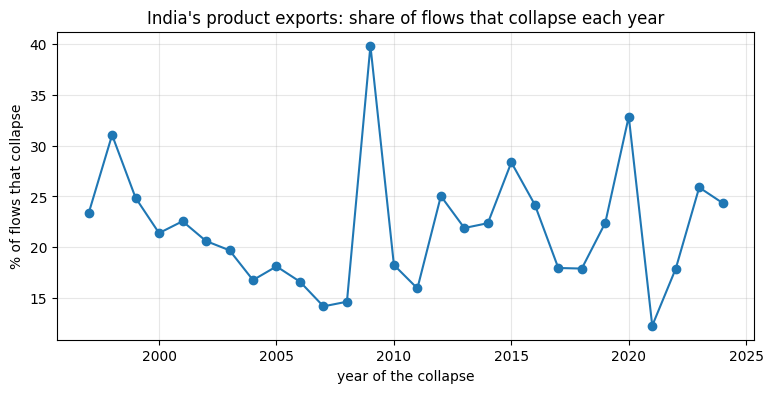

In [10]:
# First look: how often do flows collapse, year by year?
rate = {}
for year, c in zip(table["year"], table["collapse"]):
    rate.setdefault(year + 1, []).append(c)
years_sorted = sorted(rate)
plt.figure(figsize=(9, 4))
plt.plot(years_sorted, [100 * sum(rate[y]) / len(rate[y]) for y in years_sorted], marker="o")
plt.xlabel("year of the collapse"); plt.ylabel("% of flows that collapse")
plt.title("India's product exports: share of flows that collapse each year")
plt.grid(alpha=0.3); plt.show()

# Part B: Models

## Step 9: Three co-movement inputs

Collapses come in groups: when some of India's products to a country fall, others often follow, and a product
often falls in many countries at once. So for each row we look at **India's other flows in the same year** (never next year):

- `buyer_other_fell_share`: share of India's **other products to this country** that fell >26% this year
- `buyer_other_chg_mean`: average change of India's **other products to this country** this year
- `product_other_fell_share`: share of **this product to other countries** that fell >26% this year

"Other" means the row itself is left out (total minus own value).

In [11]:
by_buyer, by_product = {}, {}       # (country, year) -> [count, fell, sum of changes]
for country, hs2, year, c0 in zip(table["iso3_d"], table["hs2"], table["year"], table["chg_0"]):
    fell = 1 if c0 < -0.3 else 0
    b = by_buyer.setdefault((country, year), [0, 0, 0.0])
    b[0] += 1; b[1] += fell; b[2] += c0
    p = by_product.setdefault((hs2, year), [0, 0])
    p[0] += 1; p[1] += fell

buyer_fell, buyer_chg, product_fell = [], [], []
for country, hs2, year, c0 in zip(table["iso3_d"], table["hs2"], table["year"], table["chg_0"]):
    fell = 1 if c0 < -0.3 else 0
    n, f, s = by_buyer[(country, year)]
    buyer_fell.append((f - fell) / (n - 1) if n > 1 else None)
    buyer_chg.append((s - c0) / (n - 1) if n > 1 else None)
    n, f = by_product[(hs2, year)]
    product_fell.append((f - fell) / (n - 1) if n > 1 else None)

table["buyer_other_fell_share"] = buyer_fell
table["buyer_other_chg_mean"] = buyer_chg
table["product_other_fell_share"] = product_fell

NEW = ["buyer_other_fell_share", "buyer_other_chg_mean", "product_other_fell_share"]
ALL_INPUTS = INPUTS + NEW
print(len(ALL_INPUTS), "inputs in total")
table[NEW].describe().round(2)

24 inputs in total


,buyer_other_fell_share,buyer_other_chg_mean,product_other_fell_share
count,131223.00,131223.00,131484.00
mean,0.14,0.24,0.14
std,0.11,0.33,0.10
min,0.00,-2.46,0.00
25%,0.06,0.06,0.07
50%,0.12,0.20,0.12
75%,0.19,0.35,0.19
max,1.00,12.40,1.00


## Step 10: Scores and models

**Scores** (each calculated separately for every test year):
- **AUC**: pick one flow that collapsed and one that did not; how often does the method give the collapsed one a higher risk?
  0.5 = coin flip, 1.0 = perfect.
- **Top 10% right**: of the 10% of flows with the highest risk (the watch list), what share really collapsed?
  Compare it with the base rate (what random picking gets).
- **PR-AUC**: like AUC but focused on the collapses; random gets the base rate.
- **Brier score**: how close predicted probabilities are to what happened (lower is better). Only for the ML models.

**Methods:**
- **Volatility rule (baseline):** rank flows by how jumpy they were. No learning. Flows too new to have a volatility get the middle value.
- **Logistic regression:** fills blanks with the median, scales the inputs, fits a weighted sum.
- **Boosted trees** (scikit-learn HistGradientBoosting): 300 small trees, each fixing the mistakes of the ones before.
- **XGBoost:** the same idea from another library, as a comparison.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from xgboost import XGBClassifier

def top10(y, score):
    """Share of the top 10% highest-risk rows that really collapsed."""
    k = max(1, int(len(y) * 0.10))
    order = np.argsort(-np.asarray(score))[:k]
    return np.asarray(y)[order].mean()

def scores(y, s, prob=True):
    return {"auc": roc_auc_score(y, s), "top10": top10(y, s), "pr_auc": average_precision_score(y, s),
            "brier": brier_score_loss(y, s) if prob else np.nan}

def make_models():
    return {
        "logistic": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                  LogisticRegression(C=1.0, max_iter=2000)),
        "trees": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0),
        "xgboost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                                 subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=-1),
    }

X = table[ALL_INPUTS].astype(float)
y_all = table["collapse"].values

def test_year(train_idx, test_idx):
    """Train every model on the train rows, score every method on the test rows."""
    y = y_all[test_idx]
    vol = table.loc[test_idx, "volatility"].fillna(table.loc[train_idx, "volatility"].median()).values
    results = [{"method": "volatility rule", **scores(y, vol, prob=False)}]
    for name, m in make_models().items():
        m.fit(X.loc[train_idx], y_all[train_idx])
        results.append({"method": name, **scores(y, m.predict_proba(X.loc[test_idx])[:, 1])})
    for r in results:
        r["base_rate"] = y.mean()
    return results

## Step 11: Walk-forward test, answer years 2011-2020

A row from year *t* has its answer in *t+1*. To test answer year *Y*, we train **only** on rows whose answer was
known before *Y* (row years up to *Y−2*), and test on the rows of year *Y−1*. The model never sees the future.
A random split would let it peek at later years, so we do not use one.

In [13]:
results = []
for Y in range(2011, 2021):
    train_idx = table.index[table["year"] <= Y - 2]
    test_idx = table.index[table["year"] == Y - 1]
    for r in test_year(train_idx, test_idx):
        results.append({"answer_year": Y, "test_rows": len(test_idx), **r})
    print("done", Y)

wf = pd.DataFrame(results)
auc = wf.pivot(index="answer_year", columns="method", values="auc")
auc.round(3)

done 2011
done 2012
done 2013
done 2014
done 2015
done 2016
done 2017
done 2018
done 2019
done 2020


method,logistic,trees,volatility rule,xgboost
answer_year,,,,
2011,0.763,0.763,0.729,0.773
2012,0.666,0.715,0.681,0.721
2013,0.725,0.716,0.682,0.715
2014,0.730,0.751,0.694,0.751
2015,0.694,0.716,0.683,0.720
2016,0.715,0.726,0.698,0.730
2017,0.745,0.763,0.727,0.771
2018,0.734,0.759,0.724,0.761
2019,0.695,0.737,0.687,0.741


In [14]:
summary = wf.groupby("method")[["auc", "top10", "pr_auc", "brier"]].mean().round(3)
summary["top10_random"] = round(wf["base_rate"].mean(), 3)
print("Average over answer years 2011-2020:")
print(summary.sort_values("auc").to_string())
print()
for m in ["logistic", "trees", "xgboost"]:
    wins = sum(1 for a, b in zip(auc[m], auc["volatility rule"]) if a > b)
    print(f"{m} beats the volatility rule (AUC) in {wins} of {len(auc)} years")

Average over answer years 2011-2020:
                   auc  top10  pr_auc  brier  top10_random
method                                                    
volatility rule  0.694  0.470   0.393    NaN         0.229
logistic         0.711  0.533   0.436  0.162         0.229
trees            0.730  0.545   0.452  0.157         0.229
xgboost          0.735  0.549   0.459  0.156         0.229

logistic beats the volatility rule (AUC) in 9 of 10 years
trees beats the volatility rule (AUC) in 10 of 10 years
xgboost beats the volatility rule (AUC) in 10 of 10 years


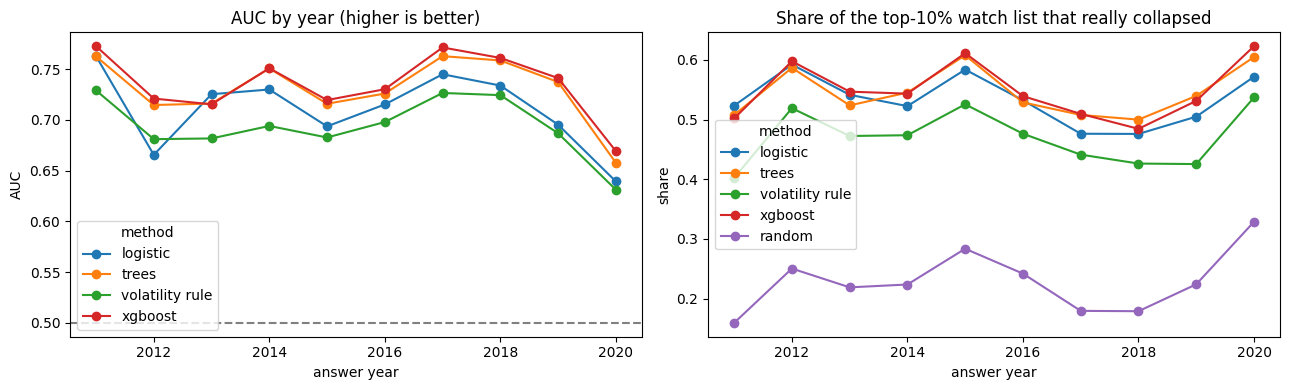

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
auc.plot(marker="o", ax=axes[0])
axes[0].axhline(0.5, color="grey", ls="--")
axes[0].set(title="AUC by year (higher is better)", xlabel="answer year", ylabel="AUC")

t10 = wf.pivot(index="answer_year", columns="method", values="top10")
t10["random"] = wf.groupby("answer_year")["base_rate"].first()
t10.plot(marker="o", ax=axes[1])
axes[1].set(title="Share of the top-10% watch list that really collapsed", xlabel="answer year", ylabel="share")
plt.tight_layout(); plt.show()

## Step 12: Frozen post-COVID test, answer years 2021-2024

Train **once** on everything with answers up to 2020, then test on 2021, 2022, 2023 and 2024 **without retraining**.
This checks whether the model still works after COVID changed trade.

In [16]:
train_idx = table.index[table["year"] <= 2019]
post = []
for Y in range(2021, 2025):
    test_idx = table.index[table["year"] == Y - 1]
    for r in test_year(train_idx, test_idx):
        post.append({"answer_year": Y, "test_rows": len(test_idx), **r})
    print("done", Y)
frozen = pd.DataFrame(post)
print("AUC:")
print(frozen.pivot(index="answer_year", columns="method", values="auc").round(3).to_string())
print("\nTop-10% watch list that really collapsed:")
print(frozen.pivot(index="answer_year", columns="method", values="top10").round(3).to_string())

done 2021
done 2022
done 2023
done 2024
AUC:
method       logistic  trees  volatility rule  xgboost
answer_year                                           
2021            0.740  0.757            0.730    0.760
2022            0.708  0.710            0.685    0.712
2023            0.674  0.701            0.660    0.705
2024            0.754  0.759            0.729    0.762

Top-10% watch list that really collapsed:
method       logistic  trees  volatility rule  xgboost
answer_year                                           
2021            0.374  0.396            0.316    0.395
2022            0.473  0.446            0.403    0.455
2023            0.541  0.578            0.483    0.584
2024            0.646  0.619            0.570    0.638


## Step 13: Which inputs matter most? (permutation importance)

Shuffle one input at a time and see how much the AUC drops. A big drop = the model relies on that input.
(Trained on answers up to 2014, measured on answer years 2016-2019.)

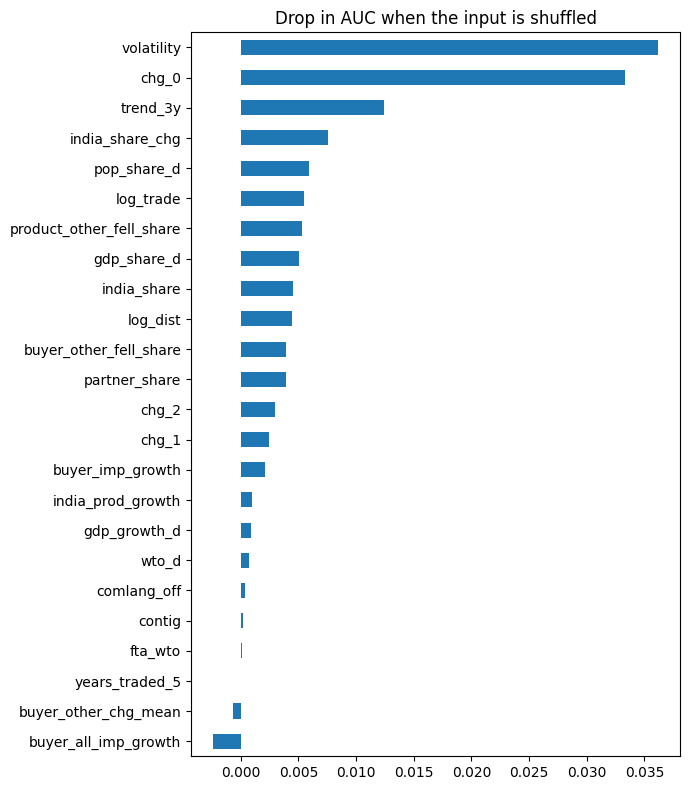

In [17]:
from sklearn.inspection import permutation_importance
tr = table.index[table["year"] < 2014]
te = table.index[(table["year"] >= 2015) & (table["year"] <= 2018)]
m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(X.loc[tr], y_all[tr])
pi = permutation_importance(m, X.loc[te], y_all[te], scoring="roc_auc", n_repeats=5, random_state=0)
importance = pd.Series(pi.importances_mean, index=ALL_INPUTS).sort_values()
importance.plot(kind="barh", figsize=(7, 8), title="Drop in AUC when the input is shuffled")
plt.tight_layout(); plt.show()

## Step 14: Save the results

These files are used for the error analysis, the SHAP explanations and the website.

In [18]:
wf.to_csv(f"{DRIVE}/results_walkforward.csv", index=False)
frozen.to_csv(f"{DRIVE}/results_frozen.csv", index=False)
table.to_csv(f"{DRIVE}/my_table.csv", index=False)       # now with the 3 co-movement inputs
print("Saved: results_walkforward.csv, results_frozen.csv, my_table.csv")

Saved: results_walkforward.csv, results_frozen.csv, my_table.csv
